# 02 · Suburb Growth & Risk (2014–2023)

**Client:** Residential property investment fund, acquisitions team
**Questions answered here:**
- **Q2:** Which suburbs had the strongest long-run growth?
- **Q7:** How volatile is each area? Where did the fund earn return *without* extra risk?
- **Bonus:** did buyers of off-the-plan units overpay, and did cheaper or pricier suburbs grow faster?

### Method: repeat-sales index (like-for-like growth)
Notebook 01 showed that medians are distorted by *what sold*. Here growth is measured the way
CoreLogic and S&P/Case-Shiller do it: compare the **same dwelling sold twice**. Its location, land and
bedrooms don't change, so the price change is market movement. Every pair feeds one regression
(Bailey-Muth-Nourse), which recovers a price index. Code: `src/repeat_sales.py`.

**Four safeguards, each explained where it's applied:**
1. **Pair filters.** These drop quick flips, subdivisions, and implausible returns that suggest a renovation or knock-down-rebuild.
2. **New-build exclusion.** This drops pairs whose first sale was a developer, off-the-plan or vacant-land sale.
3. **Shrinkage.** This stops thin-data suburbs from topping the growth rankings by luck.
4. **Noise-adjusted risk.** Risk is measured at **council** level, where there's enough data to separate real volatility from sampling noise.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
from viz_style import SEGMENT_COLORS, SEGMENT_ORDER, INK_2, MUTED, apply_style, fig_header, pct_axis, subtitle
from matplotlib.ticker import MultipleLocator
from repeat_sales import (build_pairs, exclude_new_builds, fit_index, effect_of_flag,
                          signal_volatility, shrink)

apply_style()
FIG = ROOT / "reports" / "figures"
EXPORT = ROOT / "data" / "exports"
EXPORT.mkdir(parents=True, exist_ok=True)
pd.options.display.float_format = "{:,.1f}".format

sales = pd.read_parquet(ROOT / "data/processed/sydney_sales_clean.parquet")
sales["segment"] = np.where(sales.dwelling_type == "House", "House", "Unit/Townhouse")
cpi = pd.read_csv(ROOT / "data/external/cpi_sydney_quarterly.csv").set_index("quarter")["cpi_sydney"]
cpi_year = cpi.groupby(cpi.index.str[:4].astype(int)).mean()
INFLATION_LOG = np.log(cpi_year[2023] / cpi_year[2014])   # 2014 -> 2023, used to convert to real growth
YEARS = 9

def cagr(log_growth):
    """Annualised % growth from total log growth over 2014 -> 2023."""
    return np.expm1(np.asarray(log_growth) / YEARS) * 100

suburb_council = sales.groupby("suburb").council_name.agg(lambda c: c.mode().iat[0])

## 1 · Building the repeat-sale pairs

In [2]:
pairs_all, funnel = build_pairs(sales)
pairs_all["council_name"] = pairs_all.suburb.map(suburb_council)
pairs = exclude_new_builds(pairs_all)
funnel.append(("Excluding new-build first sales (developer / off-the-plan / land)", len(pairs)))

f = pd.DataFrame(funnel, columns=["step", "pairs"])
f["removed"] = (-f.pairs.diff()).fillna(0).astype(int)
print(f"{len(pairs):,} usable pairs | median hold {pairs.years.median():.1f} years")
f

111,870 usable pairs | median hold 4.0 years


,step,pairs,removed
0,Consecutive sale pairs,154845,0
1,Same dwelling type at both sales,154806,39
2,Held at least 180 days (drops flips / re-recor...,151157,3649
3,Land area unchanged (within 5%),151004,153
4,Plausible annual return (drops renovations / e...,146047,4957
5,Excluding new-build first sales (developer / o...,111870,34177


**Why exclude new builds?** On a new estate, the first recorded sale is often the **vacant lot** or an
**off-the-plan contract** signed before the home exists. For example, a 280 m² lot in Marsden Park sold for $385k
in 2015 and as a finished house for $871k in 2023. That "growth" is the cost of building the house.
New dwellings are identified by their property ID (IDs above ~3.4M were created from about 2011) plus
whether the pair's first sale is that dwelling's first-ever recorded sale. Before this fix, Marsden Park showed
**19% annual growth**, the top of Sydney.

## 2 · How much do medians understate growth?

Sydney-wide quarterly repeat-sales index vs the median-price index, both set to 2014 Q1 = 100.

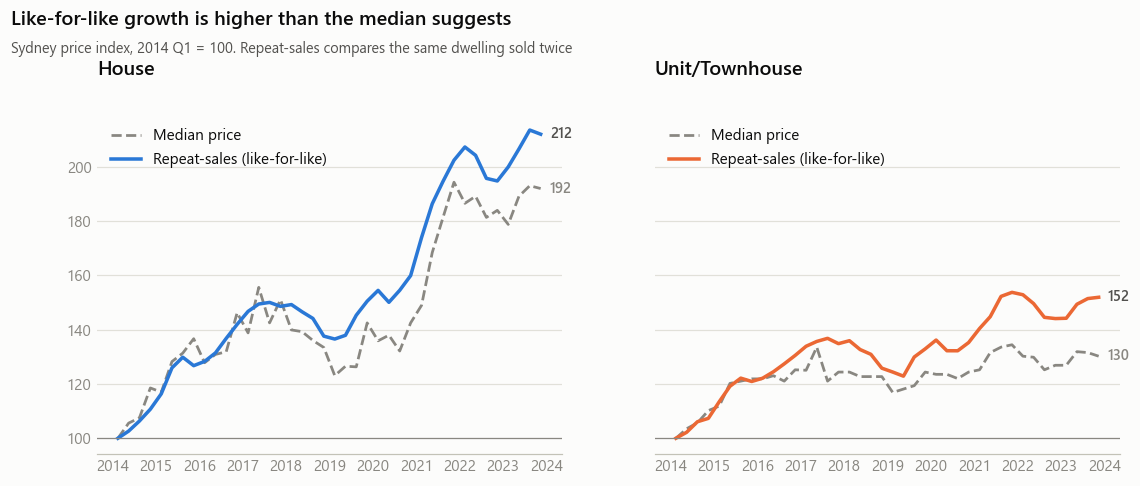

,2014→2023 growth %,median-based growth %,2017–19 downturn %,COVID boom %,2022 downturn %
House,112.0,92.0,-9.0,51.8,-6.0
Unit/Townhouse,51.9,30.2,-10.2,25.1,-6.3


In [3]:
sydney_ix, med_ix = {}, {}
for seg in SEGMENT_ORDER:
    sydney_ix[seg] = fit_index(pairs[pairs.segment == seg], "Q")
    m = sales[sales.segment == seg].groupby("quarter").purchase_price.median()
    med_ix[seg] = m / m.iloc[0] * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, seg in zip(axes, SEGMENT_ORDER):
    x = sydney_ix[seg].index.start_time + pd.Timedelta(days=45)
    ax.plot(x, med_ix[seg].values, color=MUTED, ls="--", lw=1.8, label="Median price")
    ax.plot(x, sydney_ix[seg]["index"].values, color=SEGMENT_COLORS[seg], lw=2.3, label="Repeat-sales (like-for-like)")
    for vals, col, dy in [(sydney_ix[seg]["index"].values, INK_2, 0), (med_ix[seg].values, MUTED, 0)]:
        ax.annotate(f"{vals[-1]:.0f}", (x[-1], vals[-1]), xytext=(6, dy), textcoords="offset points",
                    va="center", fontsize=9.5, fontweight="semibold", color=col)
    ax.axhline(100, color=MUTED, lw=0.8)
    ax.set_title(seg)
    ax.legend(loc="upper left")
fig_header(fig, "Like-for-like growth is higher than the median suggests",
           "Sydney price index, 2014 Q1 = 100. Repeat-sales compares the same dwelling sold twice", top=0.78)
fig.savefig(FIG / "nb2_repeat_vs_median.png")
plt.show()

def cycle(v):
    v = v["index"]
    return {"2014→2023 growth %": v.iloc[-1] - 100,
            "2017–19 downturn %": (v.loc["2018Q3":"2019Q4"].min() / v.loc["2017Q1":"2018Q2"].max() - 1) * 100,
            "COVID boom %": (v.loc["2021Q1":"2022Q3"].max() / v.loc["2018Q3":"2019Q4"].min() - 1) * 100,
            "2022 downturn %": (v.loc["2022Q2":].min() / v.loc["2021Q1":"2022Q3"].max() - 1) * 100}

summary = pd.DataFrame({seg: cycle(sydney_ix[seg]) for seg in SEGMENT_ORDER}).T
summary.insert(1, "median-based growth %", [med_ix[s].iloc[-1] - 100 for s in SEGMENT_ORDER])
summary

### Finding: medians understated like-for-like growth by about 20 points for both houses and units

| 2014 Q1 → 2023 Q4 | Median index | **Repeat-sales index** | 2017–19 fall | COVID boom | 2022 fall |
|---|---:|---:|---:|---:|---:|
| House | +92% | **+112%** | −9.0% | **+51.8%** | −6.0% |
| Unit/Townhouse | +30% | **+52%** | −10.2% | +25.1% | −6.3% |

- **An existing owner's house more than doubled in value**, much more than the median suggests. The median is
  held down because new supply keeps adding cheaper stock to the pool of sales: outer-ring estates and new apartment towers.
- **Units were not flat.** Like-for-like they rose 52%, against 30% on the median. The unit median was dragged down by the
  wave of new, smaller apartments sold over the decade.
- **The downturns were milder than they looked.** Like-for-like, 2022's fall was about 6% for both segments.

> **What this means for the fund:** don't benchmark acquisitions against median-price reports. They understate what an
> established asset actually gained. Use a repeat-sales benchmark (like CoreLogic's) for performance reporting.
>
> *Caveat:* repeat sales slightly **overstate** growth when owners renovate between sales. The filters remove extreme
> cases, but minor renovations remain, so the true figure likely sits a little below the repeat-sales line.

## 3 · Bonus: did off-the-plan buyers overpay?

For each first sale that was a **new dwelling's first-ever sale**, did it sell for more or less than the market
index predicts at resale? This is estimated by adding a flag to the repeat-sales regression, which holds market
movement constant.

In [4]:
otp = pd.DataFrame(
    [(seg, *effect_of_flag(pairs_all[pairs_all.segment == seg], "new_build_first"),
      pairs_all.loc[pairs_all.segment == seg, "new_build_first"].sum())
     for seg in SEGMENT_ORDER],
    columns=["segment", "resale vs market %", "95% CI ± pts", "new-build pairs"]).set_index("segment")
otp

,resale vs market %,95% CI ± pts,new-build pairs
segment,,,
House,3.1,0.8,5441
Unit/Townhouse,-9.0,0.3,28736


### Finding: off-the-plan unit buyers paid about a 9% premium they never recovered

- **28,736** unit pairs started with a new dwelling's first sale (developer or off-the-plan). At resale, those units
  sold for **9.0% less (±0.3%)** than the market index predicted. On an $800k unit, that's about **$72k**.
- The premium is consistent with developer pricing, marketing costs, and the "new" premium wearing off on first resale.
- For houses the effect is +3.1%. That isn't comparable: a house's "first sale" is often a vacant lot or a
  house-and-land package, so the flag mixes land and completed homes.

> **What this means for the fund:** **avoid buying new apartments off the plan.** Buying the same stock on the
> **secondary market**, after the first owner has absorbed the premium, was about 9% cheaper relative to value.
> This finding is large, precise and directly actionable.

## 4 · Q2 · Which suburbs grew fastest?

An annual repeat-sales index is fitted **per suburb** (suburbs with at least 100 pairs), giving 2014→2023 growth
and its standard error.

**Why shrinkage?** A suburb with 100 pairs has a much wider error band than one with 800. Rank on raw estimates and
the top of the list fills with *lucky* thin-data suburbs. **Empirical-Bayes shrinkage** pulls each estimate toward
the Sydney average in proportion to its uncertainty: precise estimates barely move, and noisy ones move a lot.
It's the same idea as batting averages early in a season. Rankings use the shrunk estimate.

In [5]:
MIN_PAIRS = 100
rows = []
for (seg, sub), g in pairs.groupby(["segment", "suburb"]):
    if len(g) < MIN_PAIRS:
        continue
    ix = fit_index(g, "Y")
    if len(ix) < 10:
        continue
    rows.append({"segment": seg, "suburb": sub, "council": suburb_council[sub], "pairs": len(g),
                 "log_growth": ix.log_index.iloc[-1], "se": ix.se.iloc[-1]})
sub = pd.DataFrame(rows)

parts = []
for seg, x in sub.groupby("segment"):
    x = x.copy()
    x["log_growth_shrunk"], tau = shrink(x.log_growth, x.se)
    print(f"{seg}: {len(x)} suburbs | true spread of growth between suburbs (tau) = {tau:.3f} log pts")
    parts.append(x)
sub = pd.concat(parts)

sub["nominal_cagr_%"] = cagr(sub.log_growth_shrunk)
sub["real_cagr_%"] = cagr(sub.log_growth_shrunk - INFLATION_LOG)
sub["real_cagr_raw_%"] = cagr(sub.log_growth - INFLATION_LOG)
sub["real_ci_low_%"] = cagr(sub.log_growth - 1.96 * sub.se - INFLATION_LOG)
sub["real_ci_high_%"] = cagr(sub.log_growth + 1.96 * sub.se - INFLATION_LOG)
med_2023 = sales[sales.year == 2023].groupby(["segment", "suburb"]).purchase_price.median()
med_2014 = sales[sales.year == 2014].groupby(["segment", "suburb"]).purchase_price.median()
sub["median_2014"] = [med_2014.get((s, b), np.nan) for s, b in zip(sub.segment, sub.suburb)]
sub["median_2023"] = [med_2023.get((s, b), np.nan) for s, b in zip(sub.segment, sub.suburb)]
sub["rank"] = sub.groupby("segment")["real_cagr_%"].rank(ascending=False).astype(int)

print("\nShrinkage in action: the biggest movers")
sub.assign(moved=(sub["real_cagr_raw_%"] - sub["real_cagr_%"]).abs()).nlargest(5, "moved")[
    ["segment", "suburb", "pairs", "real_cagr_raw_%", "real_cagr_%"]]

House: 209 suburbs | true spread of growth between suburbs (tau) = 0.097 log pts
Unit/Townhouse: 173 suburbs | true spread of growth between suburbs (tau) = 0.139 log pts

Shrinkage in action: the biggest movers


,segment,suburb,pairs,real_cagr_raw_%,real_cagr_%
160,House,Revesby,140,1.6,3.3
16,House,Belmore,110,1.9,3.5
68,House,Freshwater,106,9.3,7.8
15,House,Bellevue Hill,128,9.0,7.5
136,House,North Narrabeen,117,8.0,6.6


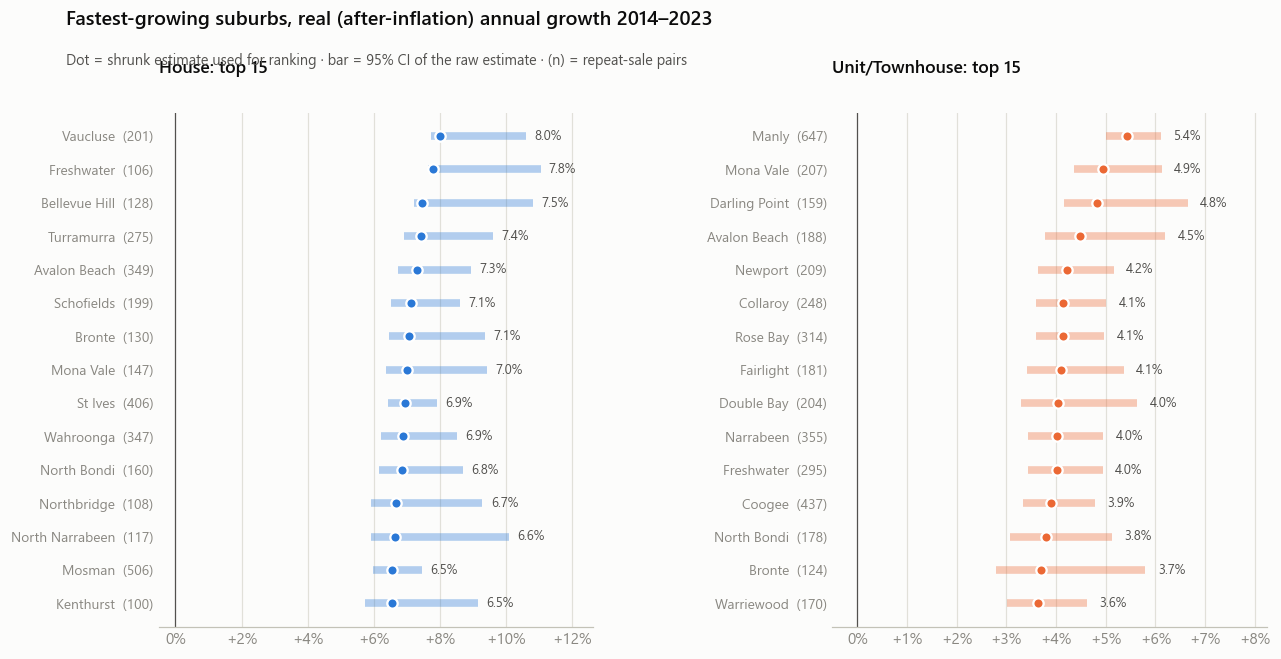

In [6]:
def ranked_dots(ax, d, color, title, label_left=False):
    d = d.iloc[::-1]
    y = np.arange(len(d))
    ax.hlines(y, d["real_ci_low_%"], d["real_ci_high_%"], color=color, alpha=0.35, lw=5)
    ax.scatter(d["real_cagr_%"], y, color=color, s=46, zorder=3, edgecolor="white", linewidth=1.5)
    for yi, (_, r) in zip(y, d.iterrows()):
        if label_left:
            ax.text(r["real_ci_low_%"] - 0.08, yi, f"{r['real_cagr_%']:.1f}%", va="center", ha="right", fontsize=8.5, color=INK_2)
        else:
            ax.text(r["real_ci_high_%"] + 0.25, yi, f"{r['real_cagr_%']:.1f}%", va="center", fontsize=8.5, color=INK_2)
    ax.set_yticks(y, [f"{s}  ({n})" for s, n in zip(d.suburb, d.pairs)], fontsize=9)
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    ax.axvline(0, color=INK_2, lw=0.8)
    pct_axis(ax, "x")
    ax.set_title(title, fontsize=11.5)

TOP = 15
fig, axes = plt.subplots(1, 2, figsize=(13, 6.4), gridspec_kw={"wspace": 0.55})
for ax, seg in zip(axes, SEGMENT_ORDER):
    d = sub[sub.segment == seg].nsmallest(TOP, "rank")
    ranked_dots(ax, d, SEGMENT_COLORS[seg], f"{seg}: top {TOP}")
    ax.set_xlim(min(0, d["real_ci_low_%"].min()) - 0.5, d["real_ci_high_%"].max() + 1.6)
fig_header(fig, "Fastest-growing suburbs, real (after-inflation) annual growth 2014–2023",
           "Dot = shrunk estimate used for ranking · bar = 95% CI of the raw estimate · (n) = repeat-sale pairs", top=0.84)
fig.savefig(FIG / "q2_top_suburbs.png")
plt.show()

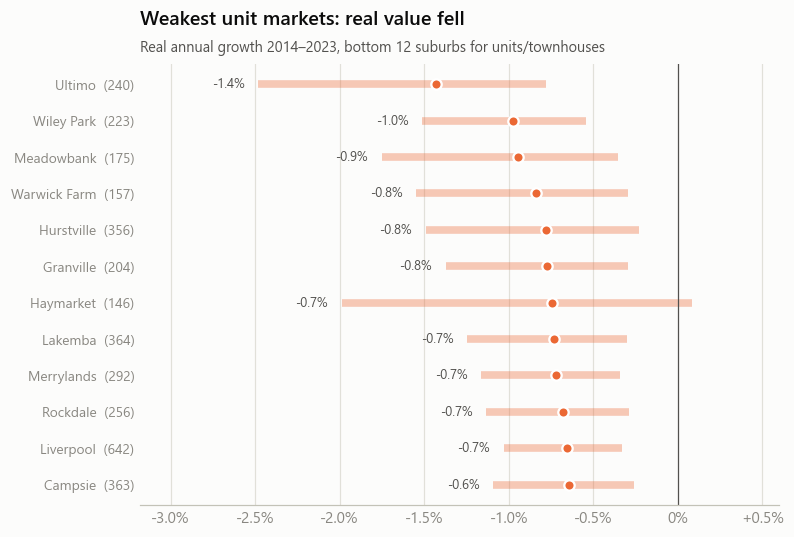

,suburb,council,pairs,real_cagr_%,median_2023
238,Campsie,Canterbury-Bankstown,363,-0.6,"614,000.0"
299,Liverpool,Liverpool,642,-0.7,"481,000.0"
341,Rockdale,Bayside,256,-0.7,"678,500.0"
310,Merrylands,Cumberland,292,-0.7,"480,000.0"
291,Lakemba,Canterbury-Bankstown,364,-0.7,"397,000.0"
275,Haymarket,City of Sydney,146,-0.7,"991,500.0"
271,Granville,City of Parramatta,204,-0.8,"522,000.0"
281,Hurstville,Georges River,356,-0.8,"715,000.0"
367,Warwick Farm,Liverpool,157,-0.8,"430,000.0"
308,Meadowbank,Ryde,175,-0.9,"730,000.0"


In [7]:
BOTTOM = 12
fig, ax = plt.subplots(figsize=(7.5, 5.2))
d = sub[sub.segment == "Unit/Townhouse"].nlargest(BOTTOM, "rank").sort_values("rank")
ranked_dots(ax, d.iloc[::-1], SEGMENT_COLORS["Unit/Townhouse"], "", label_left=True)
ax.set_xlim(d["real_ci_low_%"].min() - 0.7, 0.6)
ax.xaxis.set_major_locator(MultipleLocator(0.5))
pct_axis(ax, "x", decimals=1)
ax.set_title("Weakest unit markets: real value fell")
subtitle(ax, "Real annual growth 2014–2023, bottom 12 suburbs for units/townhouses")
fig.savefig(FIG / "q2_weakest_units.png")
plt.show()
d[["suburb", "council", "pairs", "real_cagr_%", "median_2023"]]

### Finding (Q2): long-run winners cluster by the coast and on the North Shore. The weakest unit markets lost real value

**Houses:** the top 15 all had real growth of **6.5–8.0% a year** (Sydney median about 5.0%).
- Eastern Suburbs (Vaucluse, Bellevue Hill, Bronte, North Bondi), the **Northern Beaches** (Freshwater, Avalon Beach,
  Mona Vale, North Narrabeen) and the **Upper North Shore** (Turramurra, St Ives, Wahroonga) make up 11 of the 15.
- **Schofields** (7.1%) is the only Western Sydney suburb in the top 15.
- **Every** one of the 209 house suburbs beat inflation. The lowest was 3.1% a year real.

**Units/townhouses:** all 15 of the top suburbs are **Northern Beaches (9) or Eastern Suburbs (6)** coastal markets,
led by Manly (5.4% a year real). These are areas where new apartment supply is tightly limited.

**The weakest unit markets:** **38 of 173** unit suburbs lost value in real terms. The bottom group is CBD-fringe
student and investor stock (Ultimo −1.4%, Haymarket) and high-supply corridors in the south-west and west
(Wiley Park, Lakemba, Campsie, Liverpool, Merrylands, Granville), plus Hurstville and Rockdale.

> **What this means for the fund:** for units, **scarcity drove returns.** The only unit markets that clearly beat
> inflation are ones where planning and geography limit new supply. Avoid unit markets with large development pipelines.

### Q2b · Did cheaper or pricier suburbs grow faster?

A popular belief is that "affordable suburbs have more room to grow". Here each suburb's 2014 median price is
compared with its like-for-like growth.

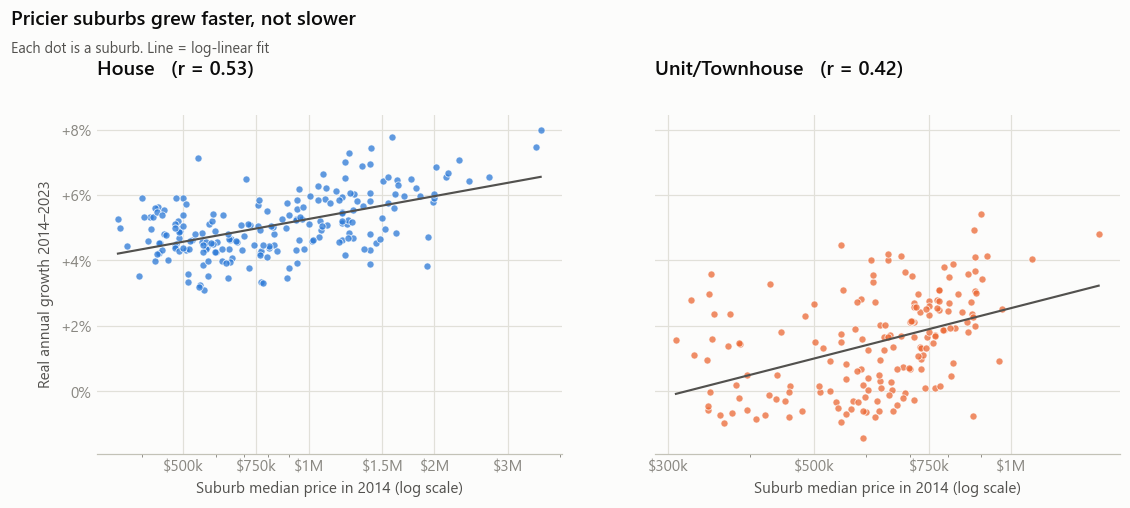

median_2014,Cheapest 25%,2nd,3rd,Priciest 25%
real CAGR % by 2014 price quartile,,,,
House,4.8,4.5,5.1,5.9
Unit/Townhouse,0.7,1.1,1.5,2.6


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
tiers = {}
for ax, seg in zip(axes, SEGMENT_ORDER):
    d = sub[(sub.segment == seg)].dropna(subset=["median_2014"])
    ax.scatter(d.median_2014, d["real_cagr_%"], s=22, color=SEGMENT_COLORS[seg], alpha=0.75,
               edgecolor="white", linewidth=0.6)
    b = np.polyfit(np.log(d.median_2014), d["real_cagr_%"], 1)
    xs = np.linspace(np.log(d.median_2014.min()), np.log(d.median_2014.max()), 50)
    ax.plot(np.exp(xs), np.polyval(b, xs), color=INK_2, lw=1.4)
    r = np.corrcoef(np.log(d.median_2014), d["real_cagr_%"])[0, 1]
    ax.set_xscale("log")
    ticks = [t for t in [3e5, 5e5, 7.5e5, 1e6, 1.5e6, 2e6, 3e6, 5e6] if d.median_2014.min() * 0.9 <= t <= d.median_2014.max() * 1.1]
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v/1e6:g}M" if v >= 1e6 else f"${v/1e3:.0f}k"))
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_title(f"{seg}   (r = {r:.2f})")
    ax.set_xlabel("Suburb median price in 2014 (log scale)")
    ax.grid(axis="x", visible=True)
    tiers[seg] = d.groupby(pd.qcut(d.median_2014, 4, labels=["Cheapest 25%", "2nd", "3rd", "Priciest 25%"]),
                           observed=True)["real_cagr_%"].mean()
pct_axis(axes[0], decimals=0)
axes[0].set_ylabel("Real annual growth 2014–2023")
fig_header(fig, "Pricier suburbs grew faster, not slower", "Each dot is a suburb. Line = log-linear fit", top=0.78)
fig.savefig(FIG / "q2_price_tier_vs_growth.png")
plt.show()
pd.DataFrame(tiers).T.rename_axis("real CAGR % by 2014 price quartile")

### Finding (Q2b): prestige beat affordable, which contradicts a popular investment belief

| Real annual growth by 2014 price quartile | Cheapest 25% | 2nd | 3rd | Priciest 25% |
|---|---:|---:|---:|---:|
| House | 4.8% | 4.5% | 5.1% | **5.9%** |
| Unit/Townhouse | 0.7% | 1.1% | 1.5% | **2.6%** |

The correlation is **r = 0.53** for houses and **0.42** for units. Over this decade, the **most expensive suburbs grew
fastest**. The gap looks small year to year, but compounded over nine years, 5.9% vs 4.8% is about 15 extra percentage
points of real growth.

> **What this means for the fund:** "buy cheap, it has room to grow" didn't hold in 2014–2023. That said, this was a
> decade of falling interest rates, which tends to favour high-value assets. **Test whether this holds in a rising-rate
> regime** before making it a strategy.

## 5 · Q7 · Risk vs return: where did the fund earn growth without extra risk?

**Why council level?** Volatility is the year-to-year swing in the index. At suburb level, most of that swing is
*sampling noise*: with ~150 pairs, the index wobbles even if the market doesn't. Suburb-level volatility came out at
exactly zero for a dozen suburbs, which is a sign the signal is swamped. Council areas have 500–6,000 pairs each, so
the noise can be measured and removed. `signal_volatility()` subtracts the estimated noise variance.

Risk measures per council:
- **Volatility:** noise-adjusted std dev of real annual index changes.
- **2017–19 downturn:** the fall from the 2017 annual index to 2019, the one full downturn in annual data.

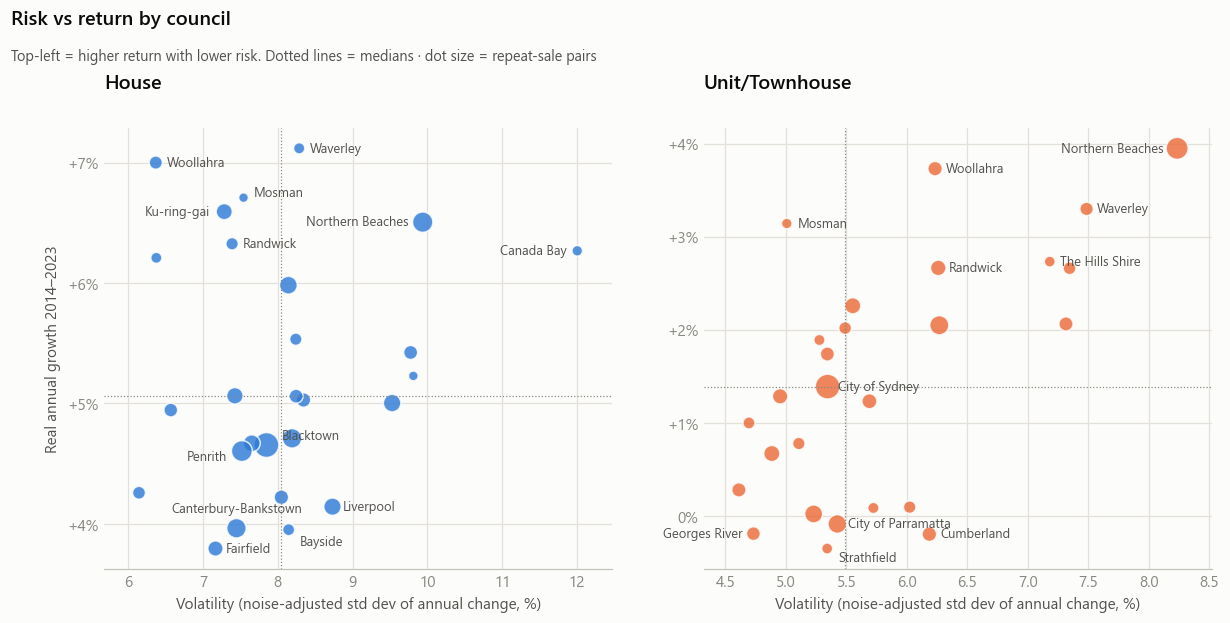

House: correlation between volatility and real growth = 0.12
Unit/Townhouse: correlation between volatility and real growth = 0.61


In [9]:
MIN_COUNCIL_PAIRS = 500
real_deflator = (cpi_year.loc[2014:2023] / cpi_year[2014]).to_numpy()
rows = []
for (seg, c), g in pairs.groupby(["segment", "council_name"]):
    if len(g) < MIN_COUNCIL_PAIRS:
        continue
    ix = fit_index(g, "Y")
    v = ix["index"].to_numpy()
    rows.append({"segment": seg, "council": c, "pairs": len(g),
                 "real_cagr_%": cagr(np.log(v[-1] / 100) - INFLATION_LOG),
                 "volatility_%": signal_volatility(ix) * 100,
                 "downturn_2017_19_%": (v[5] / v[3] - 1) * 100})
council = pd.DataFrame(rows)

# Manual label offsets (points) where auto-placement collides: (dx, dy, ha)
LABEL_NUDGE = {("House", "Canada Bay"): (-7, 0, "right"), ("House", "Bayside"): (7, -8, "left"),
               ("House", "Canterbury-Bankstown"): (0, 13, "center"),
               ("House", "Penrith"): (-10, -4, "right"), ("House", "Blacktown"): (10, 6, "left"), ("House", "Ku-ring-gai"): (-9, 0, "right"),
               ("House", "Mosman"): (7, 3, "left"), ("House", "Woollahra"): (7, 0, "left"),
               ("House", "Northern Beaches"): (-9, 0, "right"),
               ("Unit/Townhouse", "Northern Beaches"): (-9, 0, "right"),
               ("Unit/Townhouse", "Georges River"): (-7, 0, "right"),
               ("Unit/Townhouse", "Strathfield"): (7, -6, "left")}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8), gridspec_kw={"wspace": 0.18})
for ax, seg in zip(axes, SEGMENT_ORDER):
    d = council[council.segment == seg]
    ax.scatter(d["volatility_%"], d["real_cagr_%"], s=d.pairs / 25 + 20, color=SEGMENT_COLORS[seg],
               alpha=0.8, edgecolor="white", linewidth=1)
    mx, my = d["volatility_%"].median(), d["real_cagr_%"].median()
    ax.axvline(mx, color=MUTED, lw=0.8, ls=":"); ax.axhline(my, color=MUTED, lw=0.8, ls=":")
    label = pd.concat([d.nlargest(6, "real_cagr_%"), d.nsmallest(4, "real_cagr_%"),
                       d.nlargest(2, "volatility_%"), d.nlargest(2, "pairs")]).drop_duplicates("council")
    for _, r in label.iterrows():
        dx, dy, ha = LABEL_NUDGE.get((seg, r.council), (7, 0, "left"))
        ax.annotate(r.council, (r["volatility_%"], r["real_cagr_%"]), xytext=(dx, dy), textcoords="offset points",
                    fontsize=8.5, color=INK_2, ha=ha, va="center")
    pad = (d["volatility_%"].max() - d["volatility_%"].min()) * 0.08
    ax.set_xlim(d["volatility_%"].min() - pad, d["volatility_%"].max() + pad)
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.set_title(seg)
    ax.set_xlabel("Volatility (noise-adjusted std dev of annual change, %)")
    ax.grid(axis="x", visible=True)
    pct_axis(ax, decimals=0)
axes[0].set_ylabel("Real annual growth 2014–2023")
fig_header(fig, "Risk vs return by council",
           "Top-left = higher return with lower risk. Dotted lines = medians · dot size = repeat-sale pairs", top=0.80)
fig.savefig(FIG / "q7_council_risk_return.png")
plt.show()
for seg, d in council.groupby("segment"):
    print(f"{seg}: correlation between volatility and real growth = "
          f"{np.corrcoef(d['volatility_%'], d['real_cagr_%'])[0, 1]:.2f}")

In [10]:
council.sort_values(["segment", "real_cagr_%"], ascending=[True, False]).set_index(["segment", "council"])

pairs  real_cagr_%  volatility_%  \
segment        council                                                  
House          Waverley                853          7.1           8.3   
               Woollahra              1373          7.0           6.4   
               Mosman                  506          6.7           7.5   
               Ku-ring-gai            2280          6.6           7.3   
               Northern Beaches       3929          6.5           9.9   
               Randwick               1158          6.3           7.4   
               Canada Bay              706          6.3          12.0   
               Willoughby              820          6.2           6.4   
               The Hills Shire        2901          6.0           8.1   
               Ryde                   1129          5.5           8.2   
               Hornsby                1602          5.4           9.8   
               Wollondilly             512          5.2           9.8   
               Inner West             2417          5.1           7.4   
               Hawkesbury             1587          5.1           8.2   
               City of Parramatta     1756          5.0           8.3   
               Sutherland             2791          5.0           9.5   
               City of Sydney         1525          4.9           6.6   
               Campbelltown           3570          4.7           8.2   
               Camden                 2558          4.7           7.7   
               Blacktown              6152          4.7           7.8   
               Penrith                4175          4.6           7.5   
               Georges River          1295          4.3           6.1   
               Cumberland             1763          4.2           8.0   
               Liverpool              2734          4.1           8.7   
               Canterbury-Bankstown   3567          4.0           7.4   
               Bayside                1057          4.0           8.1   
               Fairfield              2005          3.8           7.2   
Unit/Townhouse Northern Beaches       4708          4.0           8.2   
               Woollahra              1749          3.7           6.2   
               Waverley               1443          3.3           7.5   
               Mosman                  702          3.1           5.0   
               The Hills Shire         783          2.7           7.2   
               Randwick               2085          2.7           6.3   
               Campbelltown           1268          2.7           7.3   
               North Sydney           2301          2.3           5.6   
               Penrith                1658          2.1           7.3   
               Sutherland             3440          2.0           6.3   
               Ku-ring-gai            1246          2.0           5.5   
               Willoughby              837          1.9           5.3   
               Canada Bay             1628          1.7           5.3   
               City of Sydney         6083          1.4           5.3   
               Inner West             2040          1.3           5.0   
               Blacktown              1920          1.2           5.7   
               Lane Cove              1060          1.0           4.7   
               Hornsby                1172          0.8           5.1   
               Bayside                2310          0.7           4.9   
               Ryde                   1680          0.3           4.6   
               Liverpool              1183          0.1           6.0   
               Fairfield               853          0.1           5.7   
               Canterbury-Bankstown   2968          0.0           5.2   
               City of Parramatta     3214         -0.1           5.4   
               Georges River          1549         -0.2           4.7   
               Cumberland             1774         -0.2           6.2   
               Strathf

### Finding (Q7): for houses, the best-performing areas were also the steadiest. For units, return came with risk

**Houses (correlation between risk and return: 0.12, so no trade-off):**
- **Woollahra** (7.0% a year real, volatility 6.4%), **Willoughby** (6.2%, 6.4%), **Ku-ring-gai** (6.6%, 7.3%),
  **Mosman** and **Randwick** sit in the ideal top-left quadrant: higher return *and* below-median volatility (8.0%).
- **In the 2017–19 downturn, prestige held its value.** Woollahra, Waverley, Willoughby and Ku-ring-gai were still *up* 2.6–4%
  from 2017 to 2019, while **Liverpool (−9.5%), Parramatta (−8.6%), Campbelltown (−7.9%) and Blacktown (−7.2%)** fell.
- Fairfield, Bayside, Canterbury-Bankstown and Liverpool had the **lowest returns (3.8–4.1%) with average risk**,
  the worst combination.

**Units (correlation 0.61, so a genuine trade-off):**
- The **Northern Beaches** has the best return (4.0% a year real) but the **highest volatility** (8.2%).
- **Mosman** (3.1%, volatility 5.0%) and **Woollahra** (3.7%, 6.2%) offer the best balance.
- Outer-west unit markets fell hardest in 2017–19: **Penrith −11.1%, Cumberland −10.0%, The Hills −9.7%**.

> **What this means for the fund:** in houses, the premium eastern and northern councils delivered the rare combination
> of **higher returns and lower risk**, with downside protection in downturns. In units, pay for growth with
> volatility (Northern Beaches) or accept moderate growth with stability (Mosman, Woollahra).

## 6 · Growth shortlist (input to the dashboard screener)

Suburbs that meet all three conditions:
1. **Top-quartile real growth** for their segment (shrunk estimate).
2. The suburb's **council is at or below median volatility**.
3. **At least 150 pairs**, so the estimate is well supported.

> Past growth isn't a forecast. This list says *where the market has rewarded owners with steady gains*.
> Notebook 03 adds valuation (Q6: is the suburb cheap *now* relative to its characteristics?).

In [11]:
council_vol = council.set_index(["segment", "council"])["volatility_%"]
vol_median = council.groupby("segment")["volatility_%"].median()
sub["council_volatility_%"] = [council_vol.get((s, c), np.nan) for s, c in zip(sub.segment, sub.council)]
q75 = sub.groupby("segment")["real_cagr_%"].transform(lambda s: s.quantile(0.75))
sub["shortlist"] = ((sub["real_cagr_%"] >= q75)
                    & (sub["council_volatility_%"] <= sub.segment.map(vol_median))
                    & (sub.pairs >= 150))
cols = ["segment", "suburb", "council", "pairs", "real_cagr_%", "council_volatility_%", "median_2023"]
sub[sub.shortlist].sort_values(["segment", "real_cagr_%"], ascending=[True, False])[cols].reset_index(drop=True)

,segment,suburb,council,pairs,real_cagr_%,council_volatility_%,median_2023
0,House,Vaucluse,Woollahra,201,8.0,6.4,"9,300,000.0"
1,House,Turramurra,Ku-ring-gai,275,7.4,7.3,"3,110,000.0"
2,House,Schofields,Blacktown,199,7.1,7.8,"1,230,000.0"
3,House,St Ives,Ku-ring-gai,406,6.9,7.3,"3,077,944.0"
4,House,Wahroonga,Ku-ring-gai,347,6.9,7.3,"2,855,000.0"
5,House,Mosman,Mosman,506,6.5,7.5,"5,300,000.0"
6,House,Kings Langley,Blacktown,155,6.5,7.8,"1,430,000.0"
7,House,Randwick,Randwick,241,6.2,7.4,"3,300,000.0"
8,House,Maroubra,Randwick,284,6.1,7.4,"2,800,000.0"
9,House,Woollahra,Woollahra,225,6.0,6.4,"5,200,000.0"


In [12]:
# Exports for the Streamlit dashboard
q_export = pd.concat([
    pd.DataFrame({"quarter": sydney_ix[s].index.astype(str), "segment": s,
                  "repeat_sales_index": sydney_ix[s]["index"].values,
                  "median_index": med_ix[s].reindex(sydney_ix[s].index.astype(str)).values})
    for s in SEGMENT_ORDER])
q_export.to_csv(EXPORT / "sydney_index_quarterly.csv", index=False)
sub.drop(columns=["log_growth", "log_growth_shrunk"]).round(4).to_csv(EXPORT / "suburb_growth.csv", index=False)
council.round(4).to_csv(EXPORT / "council_risk_return.csv", index=False)

# Per-suburb price history for the dashboard's suburb explorer
hist = (sales.groupby(["suburb", "segment", "year"])
             .agg(median_price=("purchase_price", "median"), sales=("purchase_price", "size"))
             .reset_index())
hist = hist[hist.sales >= 5]
hist.to_csv(EXPORT / "suburb_annual_medians.csv", index=False)
print("Exported:", *[p.name for p in sorted(EXPORT.glob("*.csv"))], sep="\n  ")

Exported:
  council_risk_return.csv
  suburb_annual_medians.csv
  suburb_growth.csv
  sydney_index_quarterly.csv


## Summary for the fund

1. **Like-for-like, Sydney houses rose 112% and units 52% from 2014 to 2023.** Median-based reports understate both by
   about 20 points. Benchmark with repeat-sales.
2. **Don't buy units off the plan.** Resales came in about **9% below** market value relative to what first buyers paid.
   Buying on the secondary market avoids that.
3. **Growth leaders:** Eastern Suburbs, Northern Beaches and Upper North Shore houses (6.5–8% a year real), and coastal
   units with limited supply (Manly 5.4%).
4. **Pricier suburbs outperformed** (r ≈ 0.5). The "affordable = more growth" idea didn't hold this decade.
5. **In houses, return didn't require extra risk.** Woollahra, Willoughby, Ku-ring-gai and Mosman led on growth,
   stability *and* downturn resilience. The west and south-west fell 7–10% in 2017–19.
6. **Shortlist:** 18 house suburbs and 7 unit suburbs meet all three conditions (top-quartile growth, low-risk council,
   well-supported estimate). Notably, it includes **five affordable Blacktown-council suburbs** (Schofields, Kings Langley,
   Doonside, Glenwood, Marayong; 2023 medians $0.9–1.5M) next to the prestige names. These are options for a fund
   with a lower price point.

**Exports for the dashboard app** are in `data/exports/`: the quarterly Sydney index, suburb growth with the shortlist flag, and
council risk/return.

**Next (Notebook 03):** the Domain dataset. What are beds, baths and parking worth (Q4), and which suburbs look
**undervalued today** relative to their features (Q6)? That turns this backward-looking shortlist into a buy list.